# 6. State Schemas, Reducers & MessagesState

Video 4 left a question hanging: every node so far **overwrites** whatever field it returns. What if two nodes — or one node running twice, as a loop will in Video 8 — need to *combine* their contribution to a field instead, like a conversation history where every new message should be **appended**, not replace the last one?

In Priya's words: *"The hiring manager asked why Harry got that score, and the Screener can't tell me."* Right now every node overwrites the previous one, and nothing keeps a record of how the pipeline reached its answer. This video gives it an **audit trail**: a running list of notes that every step adds to.

This video answers that with **reducers**: functions attached to a state field via `Annotated[...]` that define how a new value merges with the existing one.

**Sections**
1. Recap: the utility + the Applicant Screener pipeline (Video 5's Graph API version)
2. The merge problem, restated concretely
3. Reducers: `Annotated[type, reducer_fn]`
4. `add_messages` and `MessagesState`, in isolation
5. Why `langchain_core.messages` types, specifically
6. A custom reducer on the Applicant Screener: `evaluation_notes`
7. Decision guide: overwrite vs. custom reducer vs. `MessagesState`

## 1. Recap: the utility + the Applicant Screener pipeline

Same `llm_utils.py`, same three-node Screener from Video 4 (parse -> score -> summarize), now run on the same three candidates: Hermione (great resume), Harry (mediocre) and Ron (weak). If you're running this notebook fresh, the cells below recreate both.

In [ ]:
%pip install -r requirements.txt

In [ ]:
import os, getpass
from dotenv import load_dotenv

load_dotenv()

for env_var in ["ANTHROPIC_API_KEY", "OPENAI_API_KEY", "GOOGLE_API_KEY"]:
    if not os.environ.get(env_var):
        os.environ[env_var] = getpass.getpass(f"{env_var}: ")

In [1]:
from typing import TypedDict
from IPython.display import Image, display

from llm_utils import call_llm

# The three candidates we follow through every notebook in this story.
RESUMES = {
    "Hermione": """
Hermione Granger
7 years of experience as a senior backend software engineer.
Skills: Python, distributed systems, SQL, PostgreSQL, Kubernetes, API design.
Led a 6-person platform team at a fintech company, mentoring junior engineers.
""",
    "Harry": """
Harry Potter
4 years of experience as a software developer.
Skills: Python, SQL, REST APIs.
Informally mentored two interns. No distributed systems or Kubernetes experience.
""",
    "Ron": """
Ron Weasley
8 months of experience as a junior web developer.
Skills: HTML, CSS, basic JavaScript.
No team or leadership experience.
""",
}

PARSE_SYSTEM_PROMPT = (
    "You extract structured fields from a resume. Reply with exactly four lines, "
    "no extra commentary:\n"
    "Name: <candidate name>\n"
    "Years: <years of experience as a number>\n"
    "Skills: <comma-separated skills>\n"
    "Leadership: <one short phrase on leadership or mentoring experience, or none>"
)

RUBRIC = (
    "Score the candidate from 0-100 against this fixed rubric:\n"
    "- 5+ years experience: up to 40 points\n"
    "- Skills overlap with [Python, distributed systems, Kubernetes, SQL]: up to 40 points\n"
    "- Leadership experience mentioned: up to 20 points\n"
    "Reply with exactly two lines, no extra commentary:\n"
    "Score: <integer 0-100>\n"
    "Rationale: <one sentence>"
)


def show_graph(graph):
    """Render a compiled graph. Falls back to Mermaid text if the PNG renderer is unavailable."""
    try:
        display(Image(graph.get_graph().draw_mermaid_png()))
    except Exception:
        print(graph.get_graph().draw_mermaid())

## 2. The merge problem, restated concretely

Quick reminder from Video 4: when two nodes return a value for the *same* field, the default behavior is **last write wins** — there's no built-in "combine the old and new value" logic.

## Expected Behaviour

In [2]:
class DemoState(TypedDict):
    notes: list[str]


def add_note_a(state: DemoState) -> dict:
    return {"notes": state["notes"] + ["note from A"]}


def add_note_b(state: DemoState) -> dict:
    # Doesn't see A's update merged in yet if these ran in parallel - and even
    # run sequentially, this node has to remember to re-append manually.
    return {"notes": state["notes"] + ["note from B"]}


# Sequential, so this "works" only because each node manually re-reads state["notes"].
# The moment two nodes run in parallel (Video 9) and both read the *same* starting
# state, one node's write clobbers the other's unless something smarter merges them.
demo_a = add_note_a({"notes": []})
demo_b = add_note_b({"notes": demo_a["notes"]})
demo_b

{'notes': ['note from A', 'note from B']}

That worked, but only because every node remembered to manually re-append to the *previous* value. Forget that once, or run two nodes in parallel against the *same* starting state, and one write silently clobbers the other. A **reducer** moves that merge logic out of every node and onto the field itself, once.

## 3. Reducers: `Annotated[type, reducer_fn]`

Attach a reducer to a field by annotating its type: `Annotated[list[str], operator.add]`. Now, instead of a node's return value *replacing* the field, LangGraph calls the reducer with `(current_value, new_value)` and stores whatever it returns. For a list field, `operator.add` is just list concatenation — i.e. append.

In [3]:
import operator
from typing import Annotated
from langgraph.graph import StateGraph, START, END


class ReducerDemoState(TypedDict):
    notes: Annotated[list[str], operator.add]


def node_a(state: ReducerDemoState) -> dict:
    return {"notes": ["note from A"]}  # just this node's contribution, not the running total


def node_b(state: ReducerDemoState) -> dict:
    return {"notes": ["note from B"]}


reducer_demo_builder = StateGraph(ReducerDemoState)
reducer_demo_builder.add_node("node_a", node_a)
reducer_demo_builder.add_node("node_b", node_b)
reducer_demo_builder.add_edge(START, "node_a")
reducer_demo_builder.add_edge("node_a", "node_b")
reducer_demo_builder.add_edge("node_b", END)

reducer_demo_graph = reducer_demo_builder.compile()
reducer_demo_graph.invoke({"notes": []})

{'notes': ['note from A', 'note from B']}

Each node now returns only *its own* contribution — `operator.add` handles combining it with whatever was already there. This is the general mechanism; `add_messages` (next) is just a reducer specialized for conversation history.

## 4. `add_messages` and `MessagesState`, in isolation

`MessagesState` is a prebuilt state schema with one field, `messages: Annotated[list[AnyMessage], add_messages]`. `add_messages` is a reducer specialized for conversations: it **appends** new messages by default, but if a new message carries the **same `id`** as an existing one, it **updates that message in place** instead of appending a duplicate — relevant later for streaming and tool-call updates (Video 10+), not needed yet.

A tiny two-turn exchange, on its own, before we need this for real:

In [4]:
from langchain_core.messages import HumanMessage, AIMessage
from langgraph.graph import MessagesState


def human_turn(state: MessagesState) -> dict:
    return {"messages": [HumanMessage(content="What does this course cover?")]}


def ai_turn(state: MessagesState) -> dict:
    return {"messages": [AIMessage(content="LangGraph: state, nodes, edges, and everything built on top of them.")]}


chat_builder = StateGraph(MessagesState)
chat_builder.add_node("human_turn", human_turn)
chat_builder.add_node("ai_turn", ai_turn)
chat_builder.add_edge(START, "human_turn")
chat_builder.add_edge("human_turn", "ai_turn")
chat_builder.add_edge("ai_turn", END)

chat_graph = chat_builder.compile()
chat_result = chat_graph.invoke({"messages": []})
for m in chat_result["messages"]:
    print(f"{m.type:>10}: {m.content}")

     human: What does this course cover?
        ai: LangGraph: state, nodes, edges, and everything built on top of them.


In [5]:
# Same id -> add_messages updates that message in place instead of appending a new one.
# We call the reducer directly: it is just a function, merge(existing_list, new_items).
from langgraph.graph.message import add_messages

history = chat_result["messages"]  # [HumanMessage, AIMessage], both already have ids
edited = AIMessage(content="LangGraph: state, nodes, edges, and everything built on them (edited).", id=history[-1].id)

merged = add_messages(history, [edited])
print(len(merged), "->", merged[-1].content)

# A message with a new id is appended instead.
other = AIMessage(content="A brand new message")
print(len(add_messages(history, [other])), "-> appended, not replaced")

2 -> LangGraph: state, nodes, edges, and everything built on them (edited).
3 -> appended, not replaced


Same id: the list stays at **2** and the last message is the edited text, so `add_messages` replaced the original. New id: the list grows to **3**, so it appended. That ID-matching behavior is what makes `add_messages` the right default for *any* conversational field, not just a convenience.

Why call the reducer directly instead of invoking the graph again? Without a checkpointer, every `invoke` starts from an empty state, so there would be no earlier message for the id to match. Reducers only merge into whatever is already in state. Persisting state between calls is what checkpointers do (Video 14).

## 5. Why `langchain_core.messages` types, specifically

`HumanMessage`, `AIMessage`, `ToolMessage`, and `SystemMessage` all come from `langchain_core`, not from LangGraph itself or a provider SDK. This is the one piece of LangChain this course pulls in, per the course-wide tech-stack policy: `MessagesState` and `add_messages` are built on these types under the hood, so using them is how you get that reducer for free instead of writing your own message-merging logic by hand. We won't touch `ToolMessage` until Video 10, once tools exist.

## 6. A custom reducer on the Applicant Screener: `evaluation_notes`

**Priya's problem:** the hiring manager asks *"why did Harry get that score?"* and the Screener only has the final number to show.

**The fix:** an `evaluation_notes` field that works as an audit trail. `parse_resume` and `score_against_rubric` each append their own note, and Video 9's parallel criteria-check nodes will later add more to this same list without any of them needing to know about each other's writes.

- **Input:** a resume, plus an empty `evaluation_notes` list.
- **Output:** the usual fields, plus `evaluation_notes`: one entry per step, in order.

Reducers aren't just for messages. They're a general mechanism for *any* field that should accumulate rather than overwrite.

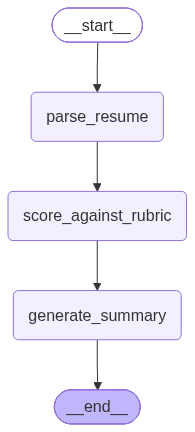

In [6]:
class ScreenerState(TypedDict):
    resume_text: str
    candidate_name: str
    years_experience: str
    skills: str
    leadership: str
    score: int
    score_rationale: str
    summary: str
    evaluation_notes: Annotated[list[str], operator.add]


def parse_resume(state: ScreenerState) -> dict:
    result = call_llm("claude", messages=[{"role": "user", "content": state["resume_text"]}], system=PARSE_SYSTEM_PROMPT)
    fields = {"candidate_name": "", "years_experience": "", "skills": "", "leadership": ""}
    for line in result.content.strip().splitlines():
        if line.startswith("Name:"):
            fields["candidate_name"] = line.removeprefix("Name:").strip()
        elif line.startswith("Years:"):
            fields["years_experience"] = line.removeprefix("Years:").strip()
        elif line.startswith("Skills:"):
            fields["skills"] = line.removeprefix("Skills:").strip()
        elif line.startswith("Leadership:"):
            fields["leadership"] = line.removeprefix("Leadership:").strip()
    fields["evaluation_notes"] = [f"Parsed fields for {fields['candidate_name'] or 'candidate'}."]
    return fields


def score_against_rubric(state: ScreenerState) -> dict:
    candidate_summary = (
        f"Name: {state['candidate_name']}\n"
        f"Years of experience: {state['years_experience']}\n"
        f"Skills: {state['skills']}\n"
        f"Leadership: {state['leadership']}"
    )
    result = call_llm("claude", messages=[{"role": "user", "content": candidate_summary}], system=RUBRIC)
    score, rationale = 0, ""
    for line in result.content.strip().splitlines():
        if line.startswith("Score:"):
            score = int("".join(ch for ch in line if ch.isdigit()) or 0)
        elif line.startswith("Rationale:"):
            rationale = line.removeprefix("Rationale:").strip()
    return {
        "score": score,
        "score_rationale": rationale,
        "evaluation_notes": [f"Scored {score}/100: {rationale}"],
    }


def generate_summary(state: ScreenerState) -> dict:
    prompt = (
        f"Candidate: {state['candidate_name']}\n"
        f"Score: {state['score']}/100 ({state['score_rationale']})\n\n"
        "Write a two-sentence plain-text summary of this candidate for a hiring manager."
    )
    result = call_llm("claude", messages=[{"role": "user", "content": prompt}])
    return {"summary": result.content}


screener_builder = StateGraph(ScreenerState)
screener_builder.add_node("parse_resume", parse_resume)
screener_builder.add_node("score_against_rubric", score_against_rubric)
screener_builder.add_node("generate_summary", generate_summary)
screener_builder.add_edge(START, "parse_resume")
screener_builder.add_edge("parse_resume", "score_against_rubric")
screener_builder.add_edge("score_against_rubric", "generate_summary")
screener_builder.add_edge("generate_summary", END)

screener_graph = screener_builder.compile()
show_graph(screener_graph)

In [7]:
for name, resume in RESUMES.items():
    print(f"=== {name} ===")
    result = screener_graph.invoke({"resume_text": resume, "evaluation_notes": []})
    for key, value in result.items():
        if key != "resume_text":
            print(f"{key}: {value}")
    print()

=== Hermione ===
candidate_name: Hermione Granger
years_experience: 7
skills: Python, distributed systems, SQL, PostgreSQL, Kubernetes, API design
leadership: Led a 6-person platform team, mentoring junior engineers
score: 100
score_rationale: 7 years of experience exceeds the 5-year threshold, all four target skills are present, and clear leadership experience is demonstrated through leading and mentoring a 6-person team.
summary: Hermione Granger is a highly qualified candidate with 7 years of experience, exceeding the 5-year requirement, and possesses all four target skills needed for the role. She also demonstrates strong leadership capability, having successfully led and mentored a team of 6 people.
evaluation_notes: ['Parsed fields for Hermione Granger.', 'Scored 100/100: 7 years of experience exceeds the 5-year threshold, all four target skills are present, and clear leadership experience is demonstrated through leading and mentoring a 6-person team.']

=== Harry ===
candidate_n

For each candidate, `evaluation_notes` ends with **two** entries — one from `parse_resume`, one from `score_against_rubric` — even though each node only ever returned a single-item list for that field. No node had to know what the other wrote, or re-read the running list and re-append by hand like Section 2's manual version. That's the payoff: it's also *why* this matters for Video 8's loops, where a node re-running on each pass needs its contributions to keep accumulating rather than overwriting the previous pass's note, and for Video 9's parallel fan-out, where multiple nodes write to this same field in the same step.

Now when the hiring manager asks about Harry, Priya can point at the notes: what was parsed, and exactly how the score was reached.

## 7. Decision guide: overwrite vs. custom reducer vs. `MessagesState`

| Field looks like… | Use |
|---|---|
| A single current value a node replaces outright (`score`, `summary`) | Default (no `Annotated`) — overwrite is exactly what you want |
| A list/counter that should accumulate contributions across nodes or loop iterations (`evaluation_notes`) | Custom reducer: `Annotated[list[T], operator.add]` (or your own function) |
| A conversation history | `Annotated[list[AnyMessage], add_messages]`, or just use the prebuilt `MessagesState` |

One more distinction worth keeping straight for later: a reducer governs how a field **merges** on each write. It's unrelated to **long-term memory** via `Store` (Video 15), which persists data *across* separate conversation threads rather than merging writes within one.

**Next video** introduces genuine runtime branching: `add_conditional_edges`. Priya's next complaint is that Hermione, Harry and Ron all get the same treatment, even though the right next step is obviously different for each. We'll route the Screener into `reject` / `interview` / `strong_match` paths based on its score.